# BigBasket Products Analysis
Step-by-step analysis of the BigBasket product dataset (27,555 listings, 10 attributes).

## Step 1: Load the dataset

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)

PATH = '/mnt/user-data/uploads/BigBasket_Products.csv'   # change if running elsewhere
df = pd.read_csv(PATH)
print('Shape:', df.shape)

Shape: (27555, 10)


## Step 2: First 12 rows

In [2]:
df.head(12)

,index,product,category,sub_category,brand,sale_price,market_price,type,rating,description
0,1,Garlic Oil - Vegetarian Capsule 500 mg,Beauty & Hygiene,Hair Care,Sri Sri Ayurveda,220.0,220.0,Hair Oil & Serum,4.1,This Product contains Garlic Oil that is known...
1,2,Water Bottle - Orange,"Kitchen, Garden & Pets",Storage & Accessories,Mastercook,180.0,180.0,Water & Fridge Bottles,2.3,"Each product is microwave safe (without lid), ..."
2,3,"Brass Angle Deep - Plain, No.2",Cleaning & Household,Pooja Needs,Trm,119.0,250.0,Lamp & Lamp Oil,3.4,"A perfect gift for all occasions, be it your m..."
3,4,Cereal Flip Lid Container/Storage Jar - Assort...,Cleaning & Household,Bins & Bathroom Ware,Nakoda,149.0,176.0,"Laundry, Storage Baskets",3.7,Multipurpose container with an attractive desi...
4,5,Creme Soft Soap - For Hands & Body,Beauty & Hygiene,Bath & Hand Wash,Nivea,162.0,162.0,Bathing Bars & Soaps,4.4,Nivea Creme Soft Soap gives your skin the best...
5,6,Germ - Removal Multipurpose Wipes,Cleaning & Household,All Purpose Cleaners,Nature Protect,169.0,199.0,Disinfectant Spray & Cleaners,3.3,Stay protected from contamination with Multipu...
6,7,Multani Mati,Beauty & Hygiene,Skin Care,Satinance,58.0,58.0,Face Care,3.6,Satinance multani matti is an excellent skin t...
7,8,Hand Sanitizer - 70% Alcohol Base,Beauty & Hygiene,Bath & Hand Wash,Bionova,250.0,250.0,Hand Wash & Sanitizers,4.0,70%Alcohol based is gentle of hand leaves skin...
8,9,Biotin & Collagen Volumizing Hair Shampoo + Bi...,Beauty & Hygiene,Hair Care,StBotanica,1098.0,1098.0,Shampoo & Conditioner,3.5,"An exclusive blend with Vitamin B7 Biotin, Hyd..."
9,10,"Scrub Pad - Anti- Bacterial, Regular",Cleaning & Household,"Mops, Brushes & Scrubs",Scotch brite,20.0,20.0,"Utensil Scrub-Pad, Glove",4.3,Scotch Brite Anti- Bacterial Scrub Pad thoroug...


## Step 3: Description of the data

In [3]:
df.describe()

,index,sale_price,market_price,rating
count,27555.00000,27549.000000,27555.000000,18919.000000
mean,13778.00000,334.648391,382.056664,3.943295
std,7954.58767,1202.102113,581.730717,0.739217
min,1.00000,2.450000,3.000000,1.000000
25%,6889.50000,95.000000,100.000000,3.700000
50%,13778.00000,190.320000,220.000000,4.100000
75%,20666.50000,359.000000,425.000000,4.300000
max,27555.00000,112475.000000,12500.000000,5.000000


In [4]:
df.describe(include='object')

,product,category,sub_category,brand,type,description
count,27554,27555,27555,27554,27555,27440
unique,23540,11,90,2313,426,21944
top,Turmeric Powder/Arisina Pudi,Beauty & Hygiene,Skin Care,Fresho,Face Care,A brand inspired by the Greek goddess of victo...
freq,26,7867,2294,638,1508,47


## Step 4: Information about the DataFrame

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27555 entries, 0 to 27554
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   index         27555 non-null  int64  
 1   product       27554 non-null  str    
 2   category      27555 non-null  str    
 3   sub_category  27555 non-null  str    
 4   brand         27554 non-null  str    
 5   sale_price    27549 non-null  float64
 6   market_price  27555 non-null  float64
 7   type          27555 non-null  str    
 8   rating        18919 non-null  float64
 9   description   27440 non-null  str    
dtypes: float64(3), int64(1), str(6)
memory usage: 2.1 MB


## Step 5: Top & least sold products

**Note:** this dataset has **no sales or units-sold column**, so true "top/least sold" cannot be measured. I use two honest proxies:
1. **Catalogue presence**: how many listings a brand / category / product type has.
2. **Customer rating**: top and lowest rated products (only among products with a rating).

In [6]:
print('Top 10 brands by number of listings'); display(df['brand'].value_counts().head(10))
print('Least listed brands (1 listing each): ', (df['brand'].value_counts()==1).sum(), 'brands')
print('Listings per category'); display(df['category'].value_counts())
print('Top 10 product types by listings'); display(df['type'].value_counts().head(10))

Top 10 brands by number of listings


brand
Fresho              638
bb Royal            539
BB Home             428
DP                  250
Fresho Signature    171
bb Combo            168
Amul                153
INATUR              146
Himalaya            141
Dabur               138
Name: count, dtype: int64

Least listed brands (1 listing each):  505 brands
Listings per category


category
Beauty & Hygiene            7867
Gourmet & World Food        4690
Kitchen, Garden & Pets      3580
Snacks & Branded Foods      2814
Foodgrains, Oil & Masala    2676
Cleaning & Household        2675
Beverages                    885
Bakery, Cakes & Dairy        851
Baby Care                    610
Fruits & Vegetables          557
Eggs, Meat & Fish            350
Name: count, dtype: int64

Top 10 product types by listings


type
Face Care                 1508
Ayurveda                   538
Men's Deodorants           500
Shampoo & Conditioner      461
Containers Sets            415
Glassware                  415
Bathing Bars & Soaps       390
Blended Masalas            380
Body Care                  340
Gourmet Tea & Tea Bags     335
Name: count, dtype: int64

In [7]:
rated = df.dropna(subset=['rating'])
print('Highest rated products (rating 5.0 count):', (rated.rating==5).sum())
display(rated.sort_values('rating', ascending=False)[['product','brand','category','rating']].head(10))
print('Lowest rated products')
display(rated.sort_values('rating')[['product','brand','category','rating']].head(10))

Highest rated products (rating 5.0 count): 1407


,product,brand,category,rating
12416,Single Line Soft Bound Long Book Feminine Seri...,Navneet Youva,Cleaning & Household,5.0
12413,Squash - Kokum Kadi,NaturoBell,Beverages,5.0
27502,Forest Honey - Wild,Organic Nation,Snacks & Branded Foods,5.0
20437,MaxFresh Blue Spicy Fresh Gel Toothpaste - Mum...,Colgate,Beauty & Hygiene,5.0
5985,Tea Tree Essential Oil,Kama Ayurveda,Beauty & Hygiene,5.0
27512,"Water Bottle - Fridge, Tulip, Dark Blue",Cello,"Kitchen, Garden & Pets",5.0
20315,Cleaner - Stainless Steel & Aluminum,Big D,Cleaning & Household,5.0
20327,Smooth Skin Oil - For Dry Skin,Aroma Treasures,Beauty & Hygiene,5.0
27508,Palm Jaggery/Bella Crystals,Draft,"Foodgrains, Oil & Masala",5.0
27507,Extra Crisp Sweet Corn,Daucy,Gourmet & World Food,5.0


Lowest rated products


,product,brand,category,rating
6111,Water/Juice Glass - Mario,Lyra,"Kitchen, Garden & Pets",1.0
16399,Red Chilli Sauce,Navya Food Art,Snacks & Branded Foods,1.0
25637,Urban Balance Daily Scrub Cleanser,Faces,Beauty & Hygiene,1.0
25643,Charlie - Gold Edt,Revlon,Beauty & Hygiene,1.0
2730,Body Deodorant - Hydra Energy,Wild Stone,Beauty & Hygiene,1.0
16010,All In Wash,QRAA,Beauty & Hygiene,1.0
23115,Rosehip Pure Coldpressed Oil,StBotanica,Beauty & Hygiene,1.0
3687,Caramel Chocolate Bar,Rage,Gourmet & World Food,1.0
3689,"Whole Wheat Cake - Chocolate Marble, Eggless",BHealthy,"Bakery, Cakes & Dairy",1.0
4223,Shikanji Syrup,Delight Foods,Beverages,1.0


In [8]:
# Brands with at least 30 listings, ranked by average rating
b = df.groupby('brand').agg(listings=('index','count'), avg_rating=('rating','mean')).query('listings>=30').dropna()
print('Top 5 brands by avg rating'); display(b.sort_values('avg_rating', ascending=False).head(5))
print('Bottom 5 brands by avg rating'); display(b.sort_values('avg_rating').head(5))

Top 5 brands by avg rating


,listings,avg_rating
brand,,
Karma Kettle,34,4.875000
VAHDAM,59,4.492727
Whiskas,37,4.421429
Laopala Diva,38,4.381250
Bella,62,4.366667


Bottom 5 brands by avg rating


,listings,avg_rating
brand,,
3BO,30,2.041667
Meghdoot,80,2.850000
BHealthy,32,2.952000
Dorall Collection,37,2.964286
Police,35,3.123077


## Step 6: Measuring discount on a certain item
Discount % = (market_price − sale_price) / market_price × 100.

Five rows have a sale price **above** the market price (obvious data-entry errors, e.g. a beard kit at ₹112,475 vs ₹3,300). They are flagged and excluded from discount calculations.

In [9]:
df['discount_pct'] = ((df['market_price'] - df['sale_price']) / df['market_price'] * 100).round(2)
bad = df[df['sale_price'] > df['market_price']]
print('Rows with sale_price > market_price:', len(bad))
display(bad[['product','sale_price','market_price','discount_pct']])

Rows with sale_price > market_price: 5


,product,sale_price,market_price,discount_pct
248,4mm Aluminium Induction Base Chapati Roti Tawa...,111649.0,1289.0,-8561.68
288,Arrabbiata Tomato Pasta Sauce With Chilli,22325.0,325.0,-6769.23
412,Original Care Lip Balm For 24h Moisture With S...,1114.8,140.0,-696.29
436,"Balloon - Polka Dot, 12 Inch",88899.0,129.0,-68813.95
1249,Beard Kit,112475.0,3300.0,-3308.33


In [10]:
# Discount on a specific item (change the search text to try another product)
def item_discount(text, n=5):
    m = df[df['product'].str.contains(text, case=False, na=False) & (df['sale_price']<=df['market_price'])]
    return m[['product','brand','sale_price','market_price','discount_pct']].head(n)

item_discount('Nivea Creme Soft Soap')

,product,brand,sale_price,market_price,discount_pct


In [11]:
clean_disc = df[df['sale_price'] <= df['market_price']]
print('Average discount by category (errors excluded)')
display(clean_disc.groupby('category')['discount_pct'].agg(['mean','median','max']).round(2).sort_values('mean', ascending=False))
print('Top 10 discounted products')
display(clean_disc.sort_values('discount_pct', ascending=False)[['product','brand','sale_price','market_price','discount_pct']].head(10))

Average discount by category (errors excluded)


,mean,median,max
category,,,
"Kitchen, Garden & Pets",22.16,21.17,82.51
Fruits & Vegetables,21.25,20.00,83.67
Beauty & Hygiene,12.34,10.00,80.50
"Foodgrains, Oil & Masala",11.84,5.00,65.52
Cleaning & Household,10.79,2.00,72.00
Beverages,9.57,0.00,62.25
"Eggs, Meat & Fish",8.06,1.79,60.67
Gourmet & World Food,7.87,0.00,66.69
"Bakery, Cakes & Dairy",7.66,0.00,75.00


Top 10 discounted products


,product,brand,sale_price,market_price,discount_pct
26976,Curry Leaves,Fresho,2.45,15.0,83.67
17713,Fruit & Vegetables Hand Juicer,Triones,349.00,1995.0,82.51
13318,Small Silicone Spatula With Plastic Handle - A...,HAZEL,75.00,399.0,81.20
13740,Decorative Party Light Big Star String LED Lig...,Lexton,209.00,1099.0,80.98
10438,NHS 860 Temperature Control Professional Hair ...,Nova,467.03,2395.0,80.50
4562,Concealer Brush 930,Mud,350.00,1750.0,80.00
11473,Decorative Party Light Golden Bell String LED ...,Lexton,415.00,1999.0,79.24
13265,Decorative Party Light Golden Bell String LED ...,Lexton,415.00,1999.0,79.24
10092,USB String Fairy Lights 3M 30 LED For Decorati...,Mansaa,85.00,399.0,78.70
24292,Steel Belly Shape Storage Dabba/ Container Set...,Jensons,219.00,995.0,77.99


## Step 7: Missing values

In [12]:
miss = pd.DataFrame({'missing': df.isnull().sum(), 'percent': (df.isnull().mean()*100).round(2)})
miss[miss.missing>0]

,missing,percent
product,1,0.00
brand,1,0.00
sale_price,6,0.02
rating,8636,31.34
description,115,0.42
discount_pct,6,0.02


In [13]:
print('Categories with NO ratings at all:')
display(df.groupby('category')['rating'].count().loc[lambda s: s==0])
print('Duplicate rows (ignoring index):', df.drop(columns='index').duplicated().sum())

Categories with NO ratings at all:


category
Eggs, Meat & Fish      0
Fruits & Vegetables    0
Name: rating, dtype: int64

Duplicate rows (ignoring index): 354


## Step 8: Outliers: detect and fill with the mean

Method: the **IQR rule** (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) on `sale_price`, `market_price` and `rating`. Outliers are replaced with the **mean of the non-outlier values** of that column, so extreme values don't distort the mean used to fill.

Cleaning first: drop duplicates, drop the 5 impossible-price rows and rows missing sale_price. Missing ratings are left as missing (31% missing, and two categories have none).

In [14]:
d = df.drop_duplicates(subset=[c for c in df.columns if c not in ('index','discount_pct')]).copy()
d = d[d['sale_price'].notna() & (d['sale_price'] <= d['market_price'])].copy()
print('Rows after cleaning:', len(d))

def iqr_bounds(s):
    q1, q3 = s.quantile([.25,.75]); i = q3-q1
    return q1-1.5*i, q3+1.5*i

cols = ['sale_price','market_price','rating']
rows = []
for c in cols:
    lo, hi = iqr_bounds(d[c].dropna())
    mask = (d[c] < lo) | (d[c] > hi)
    rows.append([c, round(lo,2), round(hi,2), int(mask.sum()), round(mask.mean()*100,1)])
pd.DataFrame(rows, columns=['column','lower_bound','upper_bound','n_outliers','pct_outliers'])

Rows after cleaning: 27190


,column,lower_bound,upper_bound,n_outliers,pct_outliers
0,sale_price,-289.0,735.0,2274,8.4
1,market_price,-387.5,912.5,2098,7.7
2,rating,2.8,5.2,1285,4.7


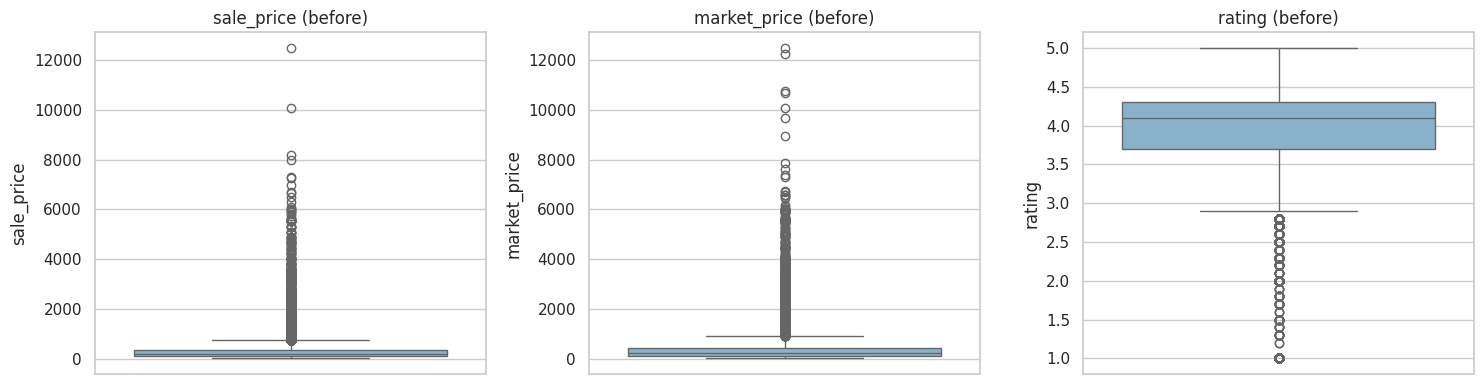

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15,4))
for a, c in zip(ax, cols):
    sns.boxplot(y=d[c], ax=a, color='#7fb3d5'); a.set_title(f'{c} (before)')
plt.tight_layout(); plt.show()

In [16]:
d_filled = d.copy()
for c in cols:
    lo, hi = iqr_bounds(d[c].dropna())
    mask = (d[c] < lo) | (d[c] > hi)
    mean_wo = d.loc[~mask, c].mean()           # mean of non-outliers
    d_filled.loc[mask, c] = mean_wo
    print(f'{c}: filled {int(mask.sum())} outliers with {mean_wo:.2f}')

d_filled['discount_pct'] = ((d_filled['market_price']-d_filled['sale_price'])/d_filled['market_price']*100).round(2)
d_filled[cols].describe().round(2)

sale_price: filled 2274 outliers with 214.16
market_price: filled 2098 outliers with 254.53
rating: filled 1285 outliers with 4.09


,sale_price,market_price,rating
count,27190.00,27190.00,18722.00
mean,214.16,254.53,4.09
std,154.78,191.77,0.46
min,2.45,3.00,2.90
25%,95.00,100.00,3.90
50%,190.00,220.00,4.10
75%,288.66,340.00,4.30
max,735.00,910.00,5.00


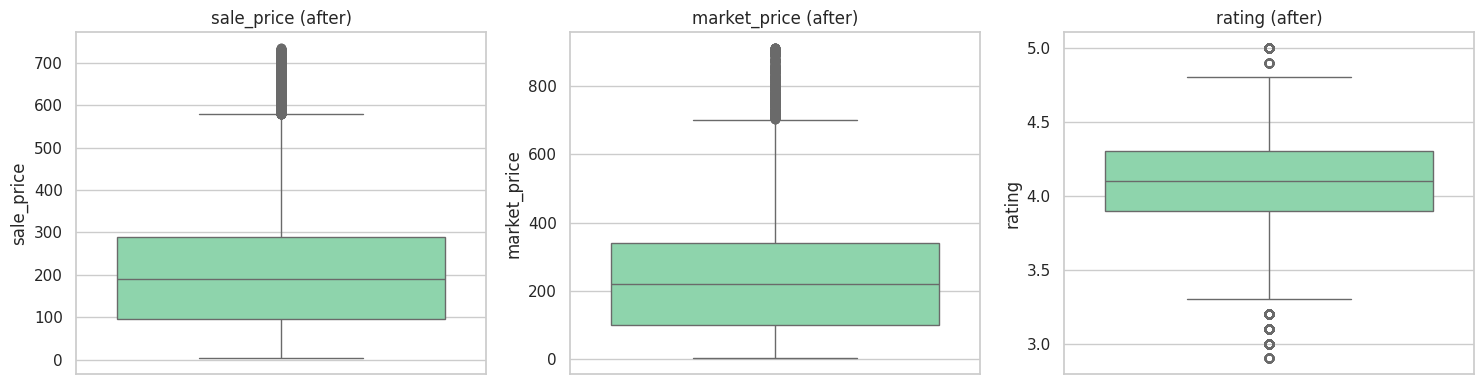

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15,4))
for a, c in zip(ax, cols):
    sns.boxplot(y=d_filled[c], ax=a, color='#82e0aa'); a.set_title(f'{c} (after)')
plt.tight_layout(); plt.show()
d_filled.to_csv('BigBasket_Products_cleaned.csv', index=False)

**Caveat:** prices are heavily right-skewed, so the IQR rule flags many legitimate expensive products (e.g. appliances, gift sets) as outliers. Replacing them with the mean flattens real variation. For serious modelling, the **median** or capping (winsorising) is usually the better choice. The original data is preserved in `df`.

## Step 9: Visualizations

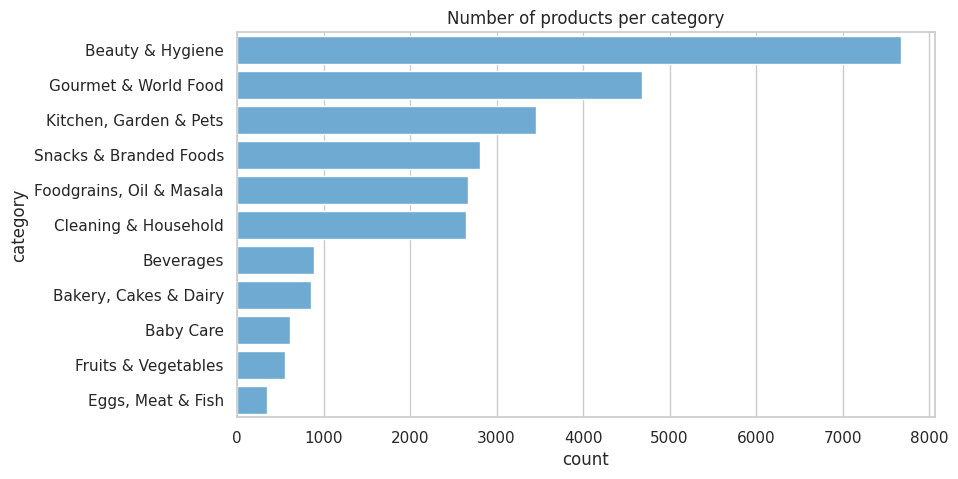

In [18]:
fig, ax = plt.subplots(figsize=(9,5))
order = d_filled['category'].value_counts().index
sns.countplot(data=d_filled, y='category', order=order, color='#5dade2', ax=ax)
ax.set_title('Number of products per category'); plt.show()

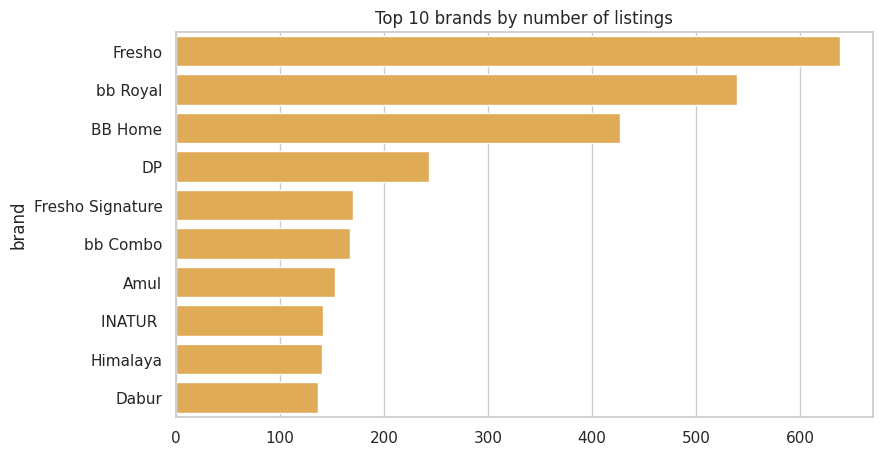

In [19]:
fig, ax = plt.subplots(figsize=(9,5))
top = d_filled['brand'].value_counts().head(10)
sns.barplot(x=top.values, y=top.index, color='#f5b041', ax=ax)
ax.set_title('Top 10 brands by number of listings'); plt.show()

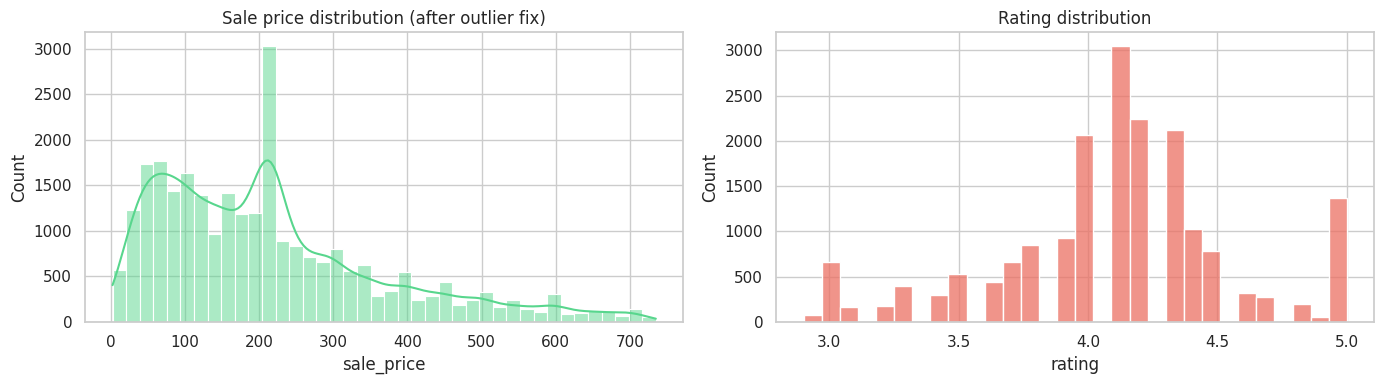

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14,4))
sns.histplot(d_filled['sale_price'], bins=40, kde=True, ax=ax[0], color='#58d68d'); ax[0].set_title('Sale price distribution (after outlier fix)')
sns.histplot(d_filled['rating'].dropna(), bins=30, ax=ax[1], color='#ec7063'); ax[1].set_title('Rating distribution')
plt.tight_layout(); plt.show()

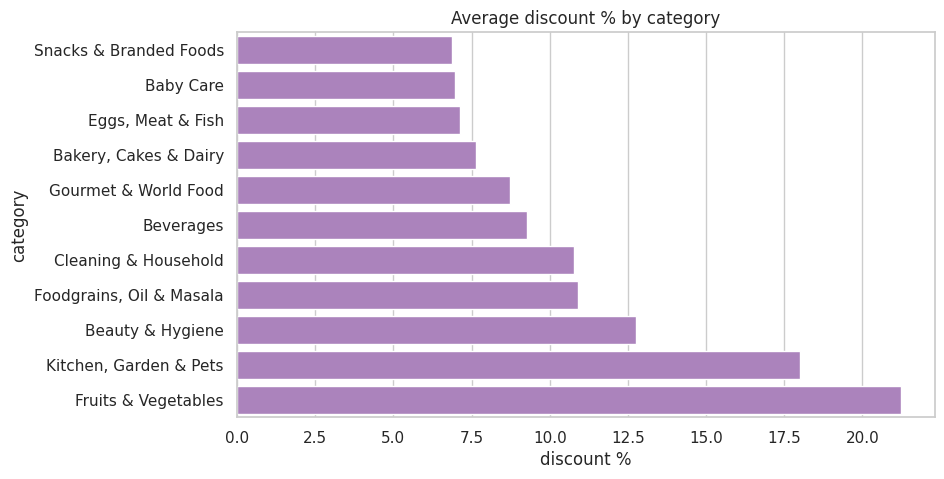

In [21]:
fig, ax = plt.subplots(figsize=(9,5))
m = d_filled.groupby('category')['discount_pct'].mean().sort_values()
sns.barplot(x=m.values, y=m.index, color='#af7ac5', ax=ax)
ax.set_title('Average discount % by category'); ax.set_xlabel('discount %'); plt.show()

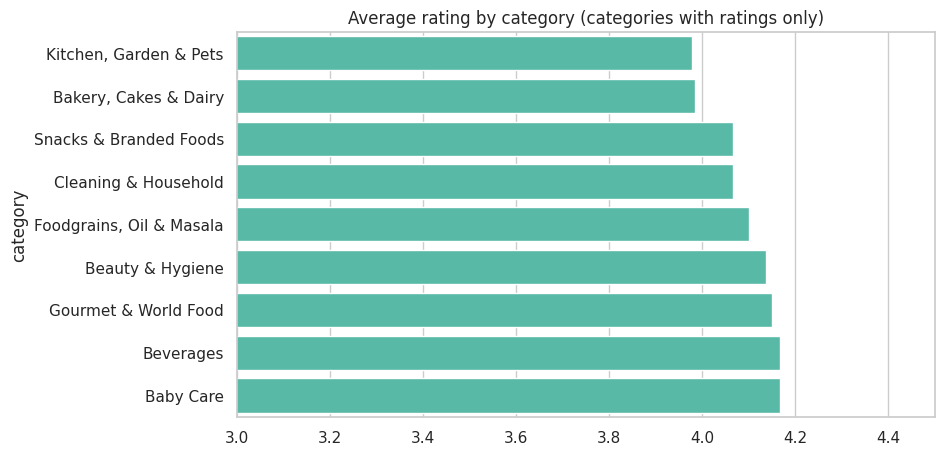

In [22]:
fig, ax = plt.subplots(figsize=(9,5))
r = d_filled.dropna(subset=['rating']).groupby('category')['rating'].mean().sort_values()
sns.barplot(x=r.values, y=r.index, color='#48c9b0', ax=ax)
ax.set_xlim(3, 4.5); ax.set_title('Average rating by category (categories with ratings only)'); plt.show()

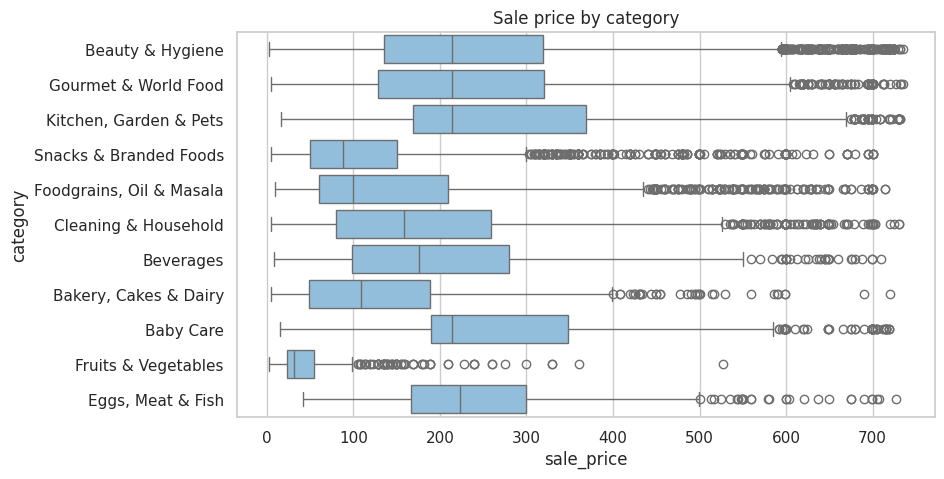

In [23]:
fig, ax = plt.subplots(figsize=(9,5))
sns.boxplot(data=d_filled, y='category', x='sale_price', order=order, ax=ax, color='#85c1e9')
ax.set_title('Sale price by category'); plt.show()

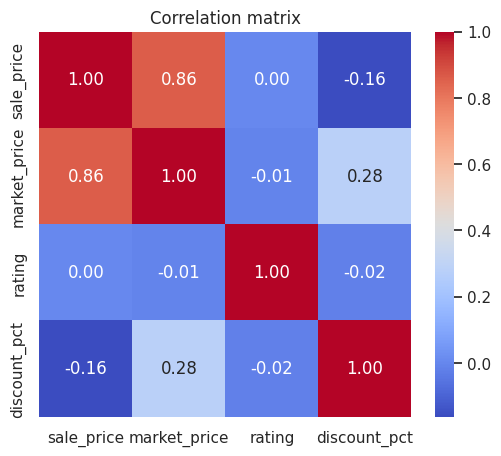

In [24]:
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(d_filled[['sale_price','market_price','rating','discount_pct']].corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=ax)
ax.set_title('Correlation matrix'); plt.show()

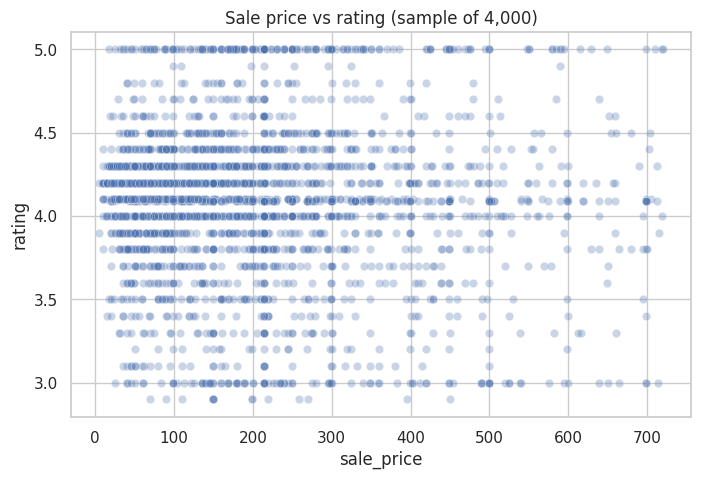

In [25]:
fig, ax = plt.subplots(figsize=(8,5))
s = d_filled.sample(4000, random_state=1)
sns.scatterplot(data=s, x='sale_price', y='rating', alpha=.3, ax=ax)
ax.set_title('Sale price vs rating (sample of 4,000)'); plt.show()

## Key takeaways
- Beauty & Hygiene is the largest category (~29% of listings); BigBasket's own labels (Fresho, bb Royal, BB Home) dominate the catalogue.
- The dataset has no sales data, so "top/least sold" is based on listings and ratings.
- Fruits & Vegetables and Eggs, Meat & Fish have no ratings.
- Price has almost no relationship with rating.
- Discounts are deepest in Bakeware, Steel Utensils and Appliances.